# Who moves first? Next-day association rules, rule features for prediction, and market regimes

DSAI 4102 Applied Data Mining, group project (exploration notebook).

This notebook keeps the approved topic (association rules on stock co-movement) and adds three things:

1. **Next-day (inter-transaction) association rules**, following Lu, Han & Feng (1998). A rule now points forward in time:
   `{TSM_DOWN today} -> {AMAT_DOWN tomorrow}`. Same-day rules can't be acted on; next-day rules can.
2. **Model comparison.** Does information from mined rules help predict whether a stock beats the market tomorrow?
   Model A uses price features only, Model B adds rule features. The finding is the *difference*, and which rules matter.
3. **Market-regime clustering.** Cluster trading days into calm / normal / stress regimes (k-means vs Gaussian mixture),
   then ask whether next-day rules behave differently in stressed markets.

**What is ours on top of Lu et al.** market-adjusted items, mining only on past years and testing on the next year,
a time-shift null model, Benjamini-Hochberg correction, a direction check that separates real direction-predicting
rules from volatility clustering, a test of whether two-item antecedents beat single ones, rule-violation features,
a trading test with costs, and regime-conditional rules.

Every number used later is stored in `KEY` and written to `outputs/lag/key_numbers.json`.

### Results at a glance (run of 21 Nov 2026, data to 13 Nov 2026)

| question | answer |
|---|---|
| Is there next-day structure in the baskets? | **In sample, yes.** Real 3-year windows give about 2.4x as many next-day rules as time-shifted chance baskets (median 212 vs 90), at every threshold tested. |
| Does it hold on the next, unseen year? | **No, not in aggregate.** Real rules: median test lift 1.05, direction right 49%. Chance rules: 1.05 and 48%. One rule in eight windows passes Benjamini-Hochberg, and it failed out of sample. |
| What is the in-sample excess then? | Mostly **volatility clustering**: busy days follow busy days, in either direction. The excess is biggest in turbulent years (2020) and in the stress regime. |
| Do two-item rules beat single ones? | Only in 31% of 35 cases. Combinations don't add information here. |
| Any persistence? | Weak: a rule that worked on one unseen year works on the next 45% of the time vs 36% if it failed (one-sided Fisher p = 0.02; rules aren't independent, so treat this as a hint). |
| Do rule features improve prediction? | **No.** All AUCs are 0.49-0.51; B - A is between -0.002 and +0.006 and every 95% interval includes 0. Nothing survives 5 bps costs. |
| Side finding | Short-term reversal (buy last week's losers) earned +13% a year gross in 2016-2020 and lost 14% a year in 2021-2026 in these stocks (t = 1.4 and -1.1, so suggestive, not significant). It flips in 2021, before ChatGPT. |
| Regimes | k-means (k = 3) finds Calm (44% of days, SPY vol 9%), Normal (28%, 13%) and Stress (28%, 25%; average correlation 0.50 vs 0.29 when calm). Stress spells match known events: 2022 bear market, COVID 2020, Q4 2018, Feb 2018, April 2025 tariffs. |
| Rules by regime | Stress days produce 2.8x more next-day rules than chance (9,346 vs 3,289), so the market is far more connected under stress, but out of sample the direction-signal share is the same as chance (42.4% vs 42.6%). Adding the regime to the model doesn't help. |

**One-sentence summary:** for 40 large, heavily traded US stocks at a daily horizon, next-day association rules
describe how volatility spreads, not which way prices go; the market prices cross-stock information within a day.

In [1]:
%pip install mlxtend scipy

Note: you may need to restart the kernel to use updated packages.


## 0. Settings
Every choice that changes a result is a named setting in this cell.

In [2]:
from pathlib import Path
from itertools import combinations
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import networkx as nx

from mlxtend.frequent_patterns import fpgrowth
from scipy.stats import hypergeom
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# ---- data ---------------------------------------------------------------------------
DATA_PATH = Path("data/prices.csv")     # adjusted closes, 2 Jun 2014 to 13 Nov 2026 (same file as final_project.ipynb)
OUT_DIR = Path("outputs/lag")
OUT_DIR.mkdir(parents=True, exist_ok=True)

GROUPS = {
    "AI enablers": ["NVDA", "AMD", "AVGO", "TSM", "MU", "QCOM", "INTC", "AMAT", "LRCX", "ASML"],
    "Big Tech": ["AAPL", "MSFT", "GOOGL", "AMZN", "META", "ORCL", "NFLX", "TSLA"],
    "Traditional software": ["ADBE", "CRM", "IBM", "CSCO", "CHGG", "INTU", "SAP", "ACN", "NOW", "WDAY", "ADSK", "CTSH"],
    "Non-tech baseline": ["JPM", "XOM", "JNJ", "PG", "KO", "WMT", "UNH", "CAT", "HD", "PFE"],
}
MARKET = "SPY"
STUDY_START = "2016-01-01"        # first basket; 2014-2015 only warms up betas and volatility
CHATGPT_DATE = "2022-12-01"

# ---- what counts as a "major move" (same as final_project.ipynb) --------------------
BETA_WINDOW = 252                 # days used to estimate each stock's beta to SPY
VOL_WINDOW = 60                   # days used to measure a stock's typical move size
Z_K = 1.0                         # major move: |residual return| >= 1 x typical move

# ---- Part 1: next-day rules -----------------------------------------------------------
MINE_YEARS = 3                    # rules used in year Y are mined on the 3 calendar years before Y
FIRST_TEST_YEAR = 2019            # 2016-2018 is the first mining window
LAG_MIN_SUPPORT = 0.02            # itemset on >= 2% of days (about 15 of 756)
LAG_MIN_CONFIDENCE = 0.20         # P(consequent tomorrow | antecedent today); a typical item occurs on ~12% of days
LAG_MIN_LIFT = 1.3
LAG_MAX_LEN = 3                   # up to two items today + one item tomorrow
MIN_FIRED_TEST = 5                # a rule is only scored out of sample if its antecedent happened >= 5 times
FDR_Q = 0.05                      # Benjamini-Hochberg false discovery rate
N_NULL = 3                        # time-shifted copies of each mining window (the chance baseline)
SEED = 42

# ---- Part 2: models ------------------------------------------------------------------
SAME_MIN_SUPPORT = 0.03           # same-day rules (used for rule-violation features)
SAME_MIN_CONFIDENCE = 0.40
SAME_MIN_LIFT = 1.5
SAME_MAX_LEN = 3
FIRST_MODEL_TEST_YEAR = 2021      # models train on 2019..Y-1 and are tested on year Y
TOP_FRACTION = 0.2                # trading test: long the top 20% of stocks, short the bottom 20%
COST_BPS = 5                      # trading cost per unit of turnover, in basis points

# ---- Part 3: regimes -------------------------------------------------------------------
K_RANGE = range(2, 7)
N_REGIMES = 3
REGIME_TRAIN_END = 2021           # regime rules: fit and mine on 2016-2021, test on 2022-2026
NETWORK_MIN_YEARS = 3             # leader network: show only edges that held in at least this many test years
REGIME_CLIP = 3.0                 # standardised state features are capped at +/-3 so a few crash days can't own a cluster

# ---- robustness: (Z_K, min support, min confidence) re-runs of Part 1 ------------------
ROBUSTNESS = [(1.0, 0.02, 0.20), (1.0, 0.03, 0.20), (1.0, 0.015, 0.15), (1.5, 0.008, 0.12), (1.5, 0.005, 0.10)]

In [3]:
# Colours: group colours pass the colour-blind checks for all pairs (validated before use).
INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
GROUP_COLORS = dict(zip(GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa8"]))
MODEL_COLORS = {"A: price only": "#2a78d6", "B: price + rules": "#eb6834", "C: B + regime": "#1baf7a",
                "R: rules only": "#4a3aa8"}
REGIME_COLORS = ["#eef4fc", "#b7d3f4", "#6d9bd6"]      # one hue, light = calm, dark = stress (price line drawn on top)
REAL, NULL = "#2a78d6", MUTED
HIGHLIGHT = "#b3261e"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.8,
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
})
KEY = {}


def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png")


def mark_chatgpt(ax):
    ax.axvline(pd.Timestamp(CHATGPT_DATE), color=HIGHLIGHT, lw=1, ls="--")
    ax.text(pd.Timestamp(CHATGPT_DATE), ax.get_ylim()[1], " ChatGPT", color=HIGHLIGHT, va="top", fontsize=8)

## 1. Data and items

Same item definition as `final_project.ipynb`, so results are comparable:

* **Residual return** = stock return minus beta x SPY return (beta from the previous 252 days only). This removes
  "the whole market fell" from every basket.
* **Major move** = residual return at least 1 x the stock's own typical move (std of the previous 60 days).
* Items look like `NVDA_UP`, `IBM_DOWN`. One basket = one trading day.

In [4]:
TICKERS = [t for members in GROUPS.values() for t in members]
GROUP_OF = {t: g for g, members in GROUPS.items() for t in members}

prices = pd.read_csv(DATA_PATH, index_col=0, parse_dates=True).sort_index()[TICKERS + [MARKET]]
returns = prices.pct_change()
stock_returns, market_returns = returns[TICKERS], returns[MARKET]

betas = pd.DataFrame({t: stock_returns[t].rolling(BETA_WINDOW).cov(market_returns)
                      / market_returns.rolling(BETA_WINDOW).var() for t in TICKERS}).shift(1)   # known before today
residual_returns = stock_returns - betas.mul(market_returns, axis=0)
zscore = residual_returns / residual_returns.rolling(VOL_WINDOW).std().shift(1)                  # known before today

up = zscore >= Z_K
down = zscore <= -Z_K
up.columns = [f"{t}_UP" for t in TICKERS]
down.columns = [f"{t}_DOWN" for t in TICKERS]
items = pd.concat([up, down], axis=1).loc[STUDY_START:]
ITEMS = list(items.columns)
DAYS = items.index


def ticker_of(item):
    return item.replace("+1", "").rsplit("_", 1)[0]


def direction_of(item):
    return item.replace("+1", "").rsplit("_", 1)[1]


print(f"{len(prices)} trading days in the file, {len(items)} baskets from {DAYS[0].date()} to {DAYS[-1].date()}")
print(f"{len(ITEMS)} possible items; an item occurs on {items.mean().mean():.1%} of days on average")
KEY["data"] = {"baskets": len(items), "first_day": str(DAYS[0].date()), "last_day": str(DAYS[-1].date()),
               "mean_item_frequency": round(float(items.mean().mean()), 4)}

3134 trading days in the file, 2733 baskets from 2016-01-04 to 2026-11-13
80 possible items; an item occurs on 11.9% of days on average


## Part 1. Next-day association rules (Lu, Han & Feng style)

**Extended basket.** For every day *t* we put today's items and tomorrow's items into one basket, tagging tomorrow's
with `+1`: `{NVDA_UP, TSM_DOWN, AMAT_DOWN+1, ...}`. Then we run ordinary FP-Growth and keep only rules whose
antecedent is entirely *today* and whose consequent is exactly one item *tomorrow*. Lu et al. needed a special
algorithm for this to run fast on 1990s hardware; with 80 items and a few thousand days, FP-Growth on the extended
basket finds exactly the same rules (window of one day).

**How we avoid fooling ourselves.**

* *Walk-forward:* rules for year Y are mined on the three years before Y and judged on year Y, which they never saw.
* *Null model:* we also mine "time-shifted" baskets where tomorrow's items are taken from a random other day
  (same item frequencies, same same-day structure, no real next-day link). Rules found there are chance.
* *Fisher exact test + Benjamini-Hochberg* over every possible rule, not just the mined ones.
* *Direction check:* a big move today makes **any** big move tomorrow more likely (volatility clustering). So
  `X -> Y_UP+1` is only a direction signal if, out of sample, X raises the chance of `Y_UP` tomorrow by more than it
  raises the chance of `Y_DOWN` tomorrow (test lift > mirror test lift). We compare every rule with its mirror.

In [5]:
def next_day_basket(items):
    # One row per day t: today's items, plus tomorrow's items tagged '+1'. The last day has no tomorrow.
    tomorrow = items.shift(-1)
    tomorrow.columns = [f"{c}+1" for c in items.columns]
    basket = pd.concat([items, tomorrow], axis=1).iloc[:-1]
    return basket.astype(bool)


EXT = next_day_basket(items)
NEXT_DAY = pd.Series(DAYS[1:], index=DAYS[:-1])      # the trading day after each row of EXT


def rows_for_years(years):
    # Rows of EXT whose day AND whose tomorrow both fall inside the given calendar years (no peeking past the window).
    years = set(years)
    keep = NEXT_DAY.index.year.isin(years) & NEXT_DAY.dt.year.isin(years).to_numpy()
    return NEXT_DAY.index[keep]


def time_shift_null(basket, rng):
    # Replace tomorrow's items by those of a randomly shifted day (circular shift inside the window).
    # Keeps every item's frequency and the same-day structure; breaks the real today -> tomorrow link.
    fut = [c for c in basket.columns if c.endswith("+1")]
    n = len(basket)
    shift = int(rng.integers(21, n - 21)) if n > 84 else max(1, n // 2)
    null = basket.copy()
    null[fut] = np.roll(basket[fut].to_numpy(), shift, axis=0)
    return null


print("Extended basket:", EXT.shape, "(days x items today+tomorrow)")
print("Example row:", sorted(c for c in EXT.columns[EXT.iloc[500].to_numpy()])[:12], "...")

Extended basket: (2732, 160) (days x items today+tomorrow)
Example row: ['NFLX_UP+1', 'TSM_UP+1'] ...


In [6]:
def mine_rules(basket, kind, min_support, min_confidence, min_lift, max_len):
    # FP-Growth, then build single-consequent rules from the frequent itemsets.
    #   kind="lag":  antecedent = items today, consequent = exactly one item tomorrow ('+1')
    #   kind="same": everything on the same day (used for the rule-violation features in Part 2)
    itemsets = fpgrowth(basket, min_support=min_support, use_colnames=True, max_len=max_len)
    support = dict(zip(itemsets["itemsets"], itemsets["support"]))
    n = len(basket)
    rows = []
    for itemset, sup in support.items():
        if len(itemset) < 2:
            continue
        if kind == "lag":
            future = [i for i in itemset if i.endswith("+1")]
            if len(future) != 1:
                continue
            candidates = future
        else:
            candidates = list(itemset)
        for cons in candidates:
            ante = itemset - {cons}
            conf = sup / support[ante]
            base = support[frozenset([cons])]
            lift = conf / base
            if conf < min_confidence or lift < min_lift:
                continue
            n_ante, n_both, n_cons = round(support[ante] * n), round(sup * n), round(base * n)
            p = hypergeom.sf(n_both - 1, n, n_cons, n_ante)   # P(this many co-occurrences or more by chance)
            rows.append({"antecedent": tuple(sorted(ante)), "consequent": cons, "support": sup,
                         "confidence": conf, "base_rate": base, "lift": lift,
                         "n_ante": n_ante, "n_both": n_both, "p_value": p})
    rules = pd.DataFrame(rows)
    if rules.empty:
        return rules
    rules["rule"] = rules["antecedent"].apply(" & ".join) + " -> " + rules["consequent"]
    rules["n_ante_items"] = rules["antecedent"].apply(len)
    rules["self"] = [ticker_of(c) in {ticker_of(a) for a in ante} for ante, c in zip(rules["antecedent"], rules["consequent"])]
    return rules.sort_values("lift", ascending=False).reset_index(drop=True)


N_ITEMS = len(ITEMS)
M_LAG = (N_ITEMS + math.comb(N_ITEMS, 2)) * N_ITEMS                    # every possible 1- or 2-item -> 1-item lag rule


def bh_significant(p_values, m_total, q=FDR_Q):
    # Benjamini-Hochberg over m_total possible rules (rules that were never mined count as p = 1).
    p = np.asarray(p_values, dtype=float)
    if len(p) == 0:
        return np.zeros(0, dtype=bool)
    order = np.argsort(p)
    passed = p[order] <= q * np.arange(1, len(p) + 1) / m_total
    k = np.max(np.nonzero(passed)[0]) + 1 if passed.any() else 0
    out = np.zeros(len(p), dtype=bool)
    out[order[:k]] = True
    return out


LAG_SETTINGS = dict(kind="lag", min_support=LAG_MIN_SUPPORT, min_confidence=LAG_MIN_CONFIDENCE,
                    min_lift=LAG_MIN_LIFT, max_len=LAG_MAX_LEN)

In [7]:
TODAY_IDX = {c: i for i, c in enumerate(ITEMS)}
ITEMS_NP = items.to_numpy()


def mirror(item):
    # NVDA_UP+1 <-> NVDA_DOWN+1
    return item.replace("_UP", "_TMP").replace("_DOWN", "_UP").replace("_TMP", "_DOWN")


def fired_matrix(antecedents, day_index, X_all=None):
    # Boolean matrix (days x rules): did each rule's antecedent happen on each day?
    X = (ITEMS_NP if X_all is None else X_all)[day_index]
    out = np.ones((len(day_index), len(antecedents)), dtype=bool)
    for j, ante in enumerate(antecedents):
        for a in ante:
            out[:, j] &= X[:, TODAY_IDX[a]]
    return out


def evaluate_out_of_sample(rules, test_days, X_all=None):
    # Score each rule on days it never saw: test confidence, test lift, and the mirror rule (opposite direction).
    if rules.empty or len(test_days) == 0:
        return rules.assign(scored=False) if not rules.empty else rules
    X_all = ITEMS_NP if X_all is None else X_all
    di = DAYS.get_indexer(test_days)
    nxt = DAYS.get_indexer(NEXT_DAY.loc[test_days])
    fired = fired_matrix(rules["antecedent"].tolist(), di, X_all)
    cons_idx = [TODAY_IDX[c.replace("+1", "")] for c in rules["consequent"]]
    mirr_idx = [TODAY_IDX[mirror(c).replace("+1", "")] for c in rules["consequent"]]
    Y = X_all[nxt]
    hit, hit_mirror = Y[:, cons_idx], Y[:, mirr_idx]
    n_fired = fired.sum(0)
    out = rules.copy()
    out["test_fired"] = n_fired
    with np.errstate(invalid="ignore", divide="ignore"):
        out["test_confidence"] = (fired & hit).sum(0) / n_fired
        out["test_mirror_confidence"] = (fired & hit_mirror).sum(0) / n_fired
        out["test_base_rate"] = hit.mean(0)
        out["test_mirror_base_rate"] = hit_mirror.mean(0)
        out["test_lift"] = out["test_confidence"] / out["test_base_rate"]
        out["test_mirror_lift"] = out["test_mirror_confidence"] / out["test_mirror_base_rate"]
    out["scored"] = n_fired >= MIN_FIRED_TEST
    # compare lifts, not confidences: UP and DOWN moves are not equally common
    out["direction_right"] = out["test_lift"] > out["test_mirror_lift"]
    return out


def summarise(scored_rules):
    s = scored_rules[scored_rules["scored"]]
    if s.empty:
        return {"n_scored": 0}
    return {"n_scored": len(s),
            "median_test_lift": float(s["test_lift"].median()),
            "share_test_lift_gt_1": float((s["test_lift"] > 1).mean()),
            "share_direction_right": float(s["direction_right"].mean()),
            "share_mirror_also_gt_1": float((s["test_mirror_lift"] > 1).mean())}

### 1.1 Walk-forward mining: mine on three years, test on the next one

For each test year we mine the real extended baskets and `N_NULL` time-shifted copies with the same thresholds.
If the market had no next-day structure, the real windows would produce about as many rules as the null windows,
and real rules would score no better than null rules on the unseen year.

In [8]:
TEST_YEARS = list(range(FIRST_TEST_YEAR, DAYS[-1].year + 1))


def walk_forward_rules(ext, X_all, settings, rng):
    # For each test year: mine real and time-shifted baskets on the 3 prior years, score both on the test year.
    rules_by_year, scored_by_year, null_by_year, rows = {}, {}, {}, []
    for Y in TEST_YEARS:
        train_days = rows_for_years(range(Y - MINE_YEARS, Y))
        test_days = NEXT_DAY.index[NEXT_DAY.index.year == Y]
        basket = ext.loc[train_days]
        rules = mine_rules(basket, **settings)
        rules["bh_significant"] = bh_significant(rules["p_value"], M_LAG) if len(rules) else []
        nulls = []
        for k in range(N_NULL):
            nr = mine_rules(time_shift_null(basket, rng), **settings)
            if len(nr):
                nr["bh_significant"] = bh_significant(nr["p_value"], M_LAG)
                nr["copy"] = k
                nulls.append(nr)
        nulls = pd.concat(nulls, ignore_index=True) if nulls else pd.DataFrame()
        rules_by_year[Y] = rules
        scored_by_year[Y] = evaluate_out_of_sample(rules, test_days, X_all)
        null_by_year[Y] = evaluate_out_of_sample(nulls, test_days, X_all)
        real_s, null_s = summarise(scored_by_year[Y]), summarise(null_by_year[Y]) if len(nulls) else {}
        rows.append({"test year": Y, "mined on": f"{Y - MINE_YEARS}-{Y - 1}", "train days": len(train_days),
                     "rules (real)": len(rules), "rules (null, mean)": len(nulls) / N_NULL,
                     "BH significant (real)": int(rules["bh_significant"].sum()) if len(rules) else 0,
                     "BH significant (null, mean)": nulls["bh_significant"].sum() / N_NULL if len(nulls) else 0,
                     "test lift median (real)": real_s.get("median_test_lift"),
                     "test lift median (null)": null_s.get("median_test_lift"),
                     "direction right (real)": real_s.get("share_direction_right"),
                     "direction right (null)": null_s.get("share_direction_right"),
                     "mirror also >1 (real)": real_s.get("share_mirror_also_gt_1")})
    return rules_by_year, scored_by_year, null_by_year, rows


LAG_RULES, LAG_SCORED, NULL_SCORED, yearly = walk_forward_rules(EXT, ITEMS_NP, LAG_SETTINGS, np.random.default_rng(SEED))
yearly = pd.DataFrame(yearly).set_index("test year")
yearly.to_csv(OUT_DIR / "p1_walk_forward_by_year.csv")
yearly.round(3)

,mined on,train days,rules (real),"rules (null, mean)",BH significant (real),"BH significant (null, mean)",test lift median (real),test lift median (null),direction right (real),direction right (null),mirror also >1 (real)
test year,,,,,,,,,,,
2019,2016-2018,753,201,83.000,0,0.0,1.000,1.008,0.428,0.458,0.562
2020,2017-2019,753,134,77.333,0,0.0,1.112,1.207,0.470,0.405,0.701
2021,2018-2020,755,355,110.667,0,0.0,1.077,1.077,0.479,0.467,0.577
2022,2019-2021,756,405,121.333,0,0.0,1.045,1.073,0.477,0.516,0.553
2023,2020-2022,755,410,159.333,1,0.0,1.050,1.022,0.534,0.448,0.517
2024,2021-2023,752,222,89.333,0,0.0,0.956,1.016,0.509,0.500,0.523
2025,2022-2024,752,124,74.667,0,0.0,1.030,1.051,0.484,0.478,0.629
2026,2023-2025,751,163,90.000,0,0.0,1.122,1.071,0.515,0.544,0.503


In [9]:
all_real = pd.concat([LAG_SCORED[Y].assign(test_year=Y) for Y in TEST_YEARS], ignore_index=True)
all_null = pd.concat([NULL_SCORED[Y].assign(test_year=Y) for Y in TEST_YEARS], ignore_index=True)
pooled = pd.DataFrame({"real rules": summarise(all_real), "null rules": summarise(all_null)}).T
sig = all_real[all_real["bh_significant"]]
pooled.loc["real, BH significant only"] = pd.Series(summarise(sig))
pooled.to_csv(OUT_DIR / "p1_pooled_out_of_sample.csv")

KEY["part1"] = {
    "rules_per_window_real_median": float(yearly["rules (real)"].median()),
    "rules_per_window_null_median": float(yearly["rules (null, mean)"].median()),
    "bh_significant_total_real": int(yearly["BH significant (real)"].sum()),
    "bh_significant_total_null_mean": float(yearly["BH significant (null, mean)"].sum()),
    "pooled": {k: {kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in v.items() if pd.notna(vv)}
               for k, v in pooled.T.to_dict().items()},
}
print(json.dumps(KEY["part1"], indent=1))
pooled.round(3)

{
 "rules_per_window_real_median": 211.5,
 "rules_per_window_null_median": 89.66666666666666,
 "bh_significant_total_real": 1,
 "bh_significant_total_null_mean": 0.0,
 "pooled": {
  "real rules": {
   "n_scored": 2014.0,
   "median_test_lift": 1.0495,
   "share_test_lift_gt_1": 0.5377,
   "share_direction_right": 0.4906,
   "share_mirror_also_gt_1": 0.5581
  },
  "null rules": {
   "n_scored": 2417.0,
   "median_test_lift": 1.0546,
   "share_test_lift_gt_1": 0.5499,
   "share_direction_right": 0.477,
   "share_mirror_also_gt_1": 0.5503
  },
  "real, BH significant only": {
   "n_scored": 1.0,
   "median_test_lift": 0.9158,
   "share_test_lift_gt_1": 0.0,
   "share_direction_right": 1.0,
   "share_mirror_also_gt_1": 0.0
  }
 }
}


,n_scored,median_test_lift,share_test_lift_gt_1,share_direction_right,share_mirror_also_gt_1
real rules,2014.0,1.049,0.538,0.491,0.558
null rules,2417.0,1.055,0.550,0.477,0.550
"real, BH significant only",1.0,0.916,0.000,1.000,0.000


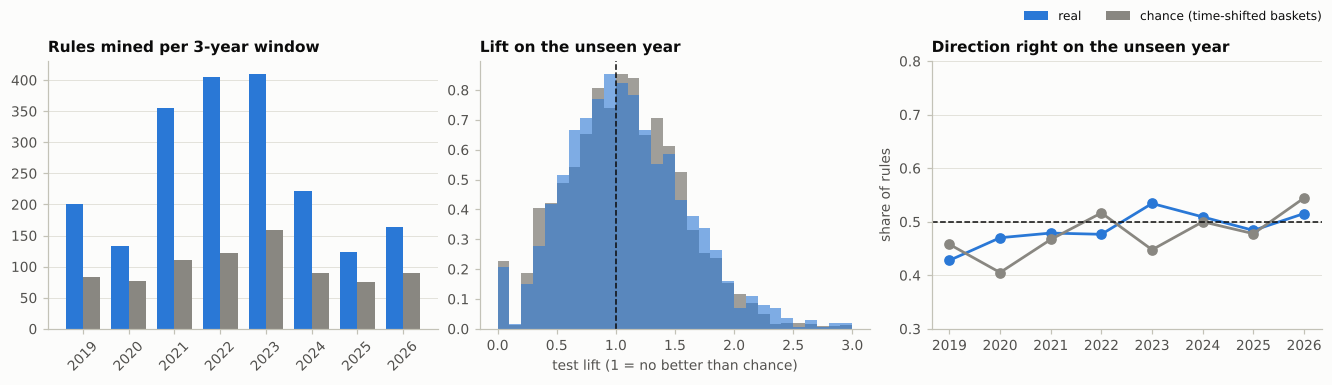

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), layout="constrained")
x = np.arange(len(TEST_YEARS))
w = 0.38
ax = axes[0]
ax.bar(x - w / 2, yearly["rules (real)"], w, color=REAL, label="real")
ax.bar(x + w / 2, yearly["rules (null, mean)"], w, color=NULL, label="chance (time-shifted baskets)")
ax.set_xticks(x, TEST_YEARS, rotation=45)
ax.set_title("Rules mined per 3-year window")
fig.legend(*ax.get_legend_handles_labels(), loc="outside upper right", ncol=2, frameon=False, fontsize=8)
ax.grid(axis="y")

ax = axes[1]
bins = np.linspace(0, 3, 31)
ax.hist(all_null.loc[all_null.scored, "test_lift"].clip(0, 3), bins=bins, color=NULL, alpha=0.8, density=True)
ax.hist(all_real.loc[all_real.scored, "test_lift"].clip(0, 3), bins=bins, color=REAL, alpha=0.6, density=True)
ax.axvline(1, color=INK, lw=1, ls="--")
ax.set_title("Lift on the unseen year")
ax.set_xlabel("test lift (1 = no better than chance)")

ax = axes[2]
ax.plot(TEST_YEARS, yearly["direction right (real)"], marker="o", color=REAL)
ax.plot(TEST_YEARS, yearly["direction right (null)"], marker="o", color=NULL)
ax.axhline(0.5, color=INK, lw=1, ls="--")
ax.set_ylim(0.3, 0.8)
ax.set_title("Direction right on the unseen year")
ax.set_ylabel("share of rules")
ax.grid(axis="y")
save(fig, "p1_walk_forward")
plt.show()

### 1.2 Volatility clustering vs real direction

A rule like `NVDA_DOWN -> AMD_UP+1` might look strong only because NVDA's big move signals a *volatile* day tomorrow,
when AMD is likely to make a big move in either direction. The table splits rules out of sample into:

* **direction signal**: test lift > 1 and higher than the mirror's (opposite direction) test lift;
* **volatility only**: test lift > 1 but the mirror's lift is at least as high;
* **failed**: test lift <= 1.

In [11]:
def classify(df):
    s = df[df["scored"]].copy()
    s["outcome"] = np.select([(s.test_lift > 1) & s.direction_right, (s.test_lift > 1)],
                             ["direction signal", "volatility only"], "failed")
    return s


real_cls, null_cls = classify(all_real), classify(all_null)
outcomes = pd.DataFrame({"real rules": real_cls["outcome"].value_counts(normalize=True),
                         "null rules": null_cls["outcome"].value_counts(normalize=True)}).fillna(0)
outcomes = outcomes.reindex(["direction signal", "volatility only", "failed"])
KEY["part1"]["outcomes"] = outcomes.round(4).to_dict()
outcomes.round(3)

,real rules,null rules
outcome,,
direction signal,0.407,0.396
volatility only,0.131,0.154
failed,0.462,0.450


### 1.3 Do two-item antecedents add anything? (the "why association rules, not correlation" test)

Pairwise lagged correlation can only say "X today predicts Y tomorrow". An association rule can say
"X **and** Z today predict Y tomorrow". That is only useful if the pair beats the better of its two single parts
on unseen data. For every scored two-item rule we compute, on the test year, the lift of each single part.

35 two-item rules scored out of sample; the pair beats its best single part in 31.4% of them


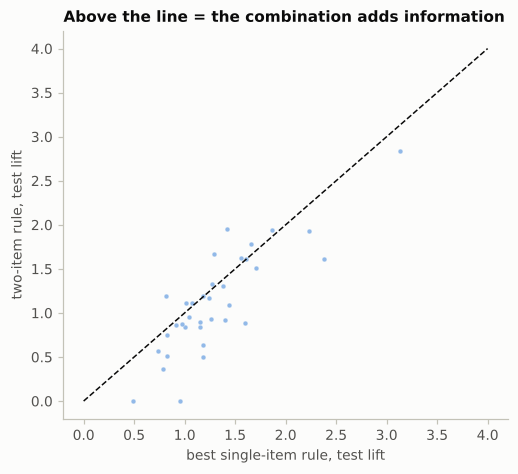

In [12]:
def single_part_lifts(rule_row, test_days):
    di = DAYS.get_indexer(test_days)
    nxt = DAYS.get_indexer(NEXT_DAY.loc[test_days])
    y = ITEMS_NP[nxt, TODAY_IDX[rule_row["consequent"].replace("+1", "")]]
    base = y.mean()
    lifts = []
    for a in rule_row["antecedent"]:
        f = ITEMS_NP[di, TODAY_IDX[a]]
        lifts.append(y[f].mean() / base if f.sum() >= MIN_FIRED_TEST and base > 0 else np.nan)
    return np.nanmax(lifts) if np.isfinite(lifts).any() else np.nan


pairs = []
for Y in TEST_YEARS:
    s = LAG_SCORED[Y]
    s = s[s["scored"] & (s["n_ante_items"] == 2)]
    test_days = NEXT_DAY.index[NEXT_DAY.index.year == Y]
    for _, r in s.iterrows():
        pairs.append({"test_year": Y, "rule": r["rule"], "pair_test_lift": r["test_lift"],
                      "best_single_test_lift": single_part_lifts(r, test_days)})
pairs = pd.DataFrame(pairs).dropna()
pair_beats = float((pairs["pair_test_lift"] > pairs["best_single_test_lift"]).mean()) if len(pairs) else np.nan
KEY["part1"]["pair_rules_scored"] = len(pairs)
KEY["part1"]["share_pair_beats_best_single"] = round(pair_beats, 4)
KEY["part1"]["median_pair_minus_single_lift"] = round(float((pairs["pair_test_lift"] - pairs["best_single_test_lift"]).median()), 4) if len(pairs) else None
print(f"{len(pairs)} two-item rules scored out of sample; the pair beats its best single part in {pair_beats:.1%} of them")

fig, ax = plt.subplots(figsize=(4.6, 4.2), layout="constrained")
ax.scatter(pairs["best_single_test_lift"].clip(0, 4), pairs["pair_test_lift"].clip(0, 4), s=10, color=REAL, alpha=0.5,
           edgecolor=SURFACE, linewidth=0.5)
ax.plot([0, 4], [0, 4], color=INK, lw=1, ls="--")
ax.set_xlabel("best single-item rule, test lift")
ax.set_ylabel("two-item rule, test lift")
ax.set_title("Above the line = the combination adds information")
save(fig, "p1_pair_vs_single")
plt.show()

### 1.3b Robustness: does the conclusion change with the thresholds?

Same walk-forward test with a bigger "major move" (1.5 x typical move) and different support / confidence. If real
rules only beat null rules under one lucky setting, that is not evidence.

In [13]:
rob_rows = []
for z_k, sup, conf in ROBUSTNESS:
    up_k, down_k = zscore >= z_k, zscore <= -z_k
    up_k.columns, down_k.columns = up.columns, down.columns
    items_k = pd.concat([up_k, down_k], axis=1).loc[STUDY_START:]
    settings = dict(LAG_SETTINGS, min_support=sup, min_confidence=conf)
    _, sc, nl, rows = walk_forward_rules(next_day_basket(items_k), items_k.to_numpy(), settings,
                                         np.random.default_rng(SEED))
    real = pd.concat(sc.values(), ignore_index=True)
    null = pd.concat([v for v in nl.values() if len(v)], ignore_index=True)
    rs, ns = summarise(real), summarise(null)
    rob_rows.append({"Z_K": z_k, "min support": sup, "min confidence": conf,
                     "rules/window real": np.median([r["rules (real)"] for r in rows]),
                     "rules/window null": np.median([r["rules (null, mean)"] for r in rows]),
                     "scored real": rs.get("n_scored"), "test lift real": rs.get("median_test_lift"),
                     "test lift null": ns.get("median_test_lift"),
                     "direction right real": rs.get("share_direction_right"),
                     "direction right null": ns.get("share_direction_right")})
robustness = pd.DataFrame(rob_rows)
robustness.to_csv(OUT_DIR / "p1_robustness.csv", index=False)
KEY["part1"]["robustness"] = robustness.round(4).to_dict(orient="records")
robustness.round(3)

,Z_K,min support,min confidence,rules/window real,rules/window null,scored real,test lift real,test lift null,direction right real,direction right null
0,1.0,0.020,0.20,211.5,89.667,2014,1.049,1.055,0.491,0.477
1,1.0,0.030,0.20,20.0,8.167,345,1.060,1.045,0.516,0.481
2,1.0,0.015,0.15,1219.0,638.000,10114,1.077,1.071,0.493,0.497
3,1.5,0.008,0.12,135.0,41.500,1496,1.141,1.000,0.417,0.402
4,1.5,0.005,0.10,1343.0,621.000,10211,1.038,1.042,0.395,0.395


### What Part 1 shows
* Real windows always produce more next-day rules than chance (first panel, and every row of the robustness table),
  so the baskets do contain next-day structure.
* On the unseen year, real and chance rules have the same lift distribution (middle panel) and the same share of
  correct directions (right panel, around 50%). The extra structure is not a stable "X leads Y" signal.
* The volatility-only and failed shares are also the same for real and chance rules (table 1.2): the mined
  rules mostly capture "a big move today means bigger moves tomorrow", which says nothing about direction.
* The one exception is the Z_K = 1.5 setting (bigger moves): median test lift 1.14 vs 1.00 for chance, but the
  direction is right only 42% of the time, i.e. again volatility, not direction.

### 1.4 Rules that held up: leaders and followers

We keep single-antecedent, cross-stock rules that were mined on past years **and** on the unseen year had
test lift > 1.2, the right direction, and an antecedent that happened at least `MIN_FIRED_TEST` times. An edge
`A -> B` means "a big move in A today has been followed by B moving tomorrow"; its width is the number of test years
in which that happened.

In [14]:
held = real_cls[(real_cls["outcome"] == "direction signal") & (real_cls["test_lift"] > 1.2)
                & (real_cls["n_ante_items"] == 1) & (~real_cls["self"])].copy()
held["leader"] = held["antecedent"].str[0].map(ticker_of)
held["follower"] = held["consequent"].map(ticker_of)
held["pattern"] = held["antecedent"].str[0].map(direction_of) + " -> " + held["consequent"].map(direction_of)

edges = held.groupby(["leader", "follower"]).agg(years=("test_year", "nunique"),
                                                 mean_test_lift=("test_lift", "mean"),
                                                 patterns=("pattern", lambda s: ", ".join(sorted(set(s))))).reset_index()
edges = edges.sort_values(["years", "mean_test_lift"], ascending=False)
edges.to_csv(OUT_DIR / "p1_leader_follower_edges.csv", index=False)

G = nx.DiGraph()
G.add_nodes_from(TICKERS)
for _, e in edges[edges["years"] >= NETWORK_MIN_YEARS].iterrows():
    G.add_edge(e["leader"], e["follower"], weight=e["years"])
leaders = pd.DataFrame({"out (leads)": dict(G.out_degree()), "in (follows)": dict(G.in_degree()),
                        "group": GROUP_OF}).sort_values("out (leads)", ascending=False)
KEY["part1"]["edges_2plus_years"] = int((edges["years"] >= 2).sum())
KEY["part1"]["edges_in_network"] = int(G.number_of_edges())
KEY["part1"]["top_leaders"] = leaders.head(5)["out (leads)"].to_dict()
KEY["part1"]["top_followers"] = leaders.sort_values("in (follows)", ascending=False).head(5)["in (follows)"].to_dict()
print("Edges seen in 2+ test years:", int((edges["years"] >= 2).sum()), f"| in {NETWORK_MIN_YEARS}+ years (drawn):", G.number_of_edges())
display(edges.head(15))
leaders.head(10)

Edges seen in 2+ test years: 138 | in 3+ years (drawn): 35


,leader,follower,years,mean_test_lift,patterns
86,CAT,XOM,5,1.715851,DOWN -> DOWN
150,INTC,AAPL,5,1.573692,"DOWN -> UP, UP -> UP"
174,JNJ,NOW,4,1.823376,UP -> UP
288,ORCL,JNJ,4,1.820735,"DOWN -> UP, UP -> UP"
43,AMD,AAPL,4,1.691934,"DOWN -> UP, UP -> UP"
379,WMT,JNJ,4,1.682662,UP -> UP
7,AAPL,NOW,4,1.582970,"UP -> DOWN, UP -> UP"
281,ORCL,ADBE,4,1.580472,UP -> UP
264,NOW,ASML,3,2.259195,UP -> DOWN
67,AVGO,AMAT,3,2.070309,"DOWN -> DOWN, UP -> DOWN"


,out (leads),in (follows),group
NOW,4,3,Traditional software
WMT,4,0,Non-tech baseline
ORCL,3,0,Big Tech
AAPL,3,4,Big Tech
QCOM,2,0,AI enablers
KO,2,4,Non-tech baseline
JNJ,2,4,Non-tech baseline
NVDA,1,0,AI enablers
HD,1,2,Non-tech baseline
XOM,1,5,Non-tech baseline


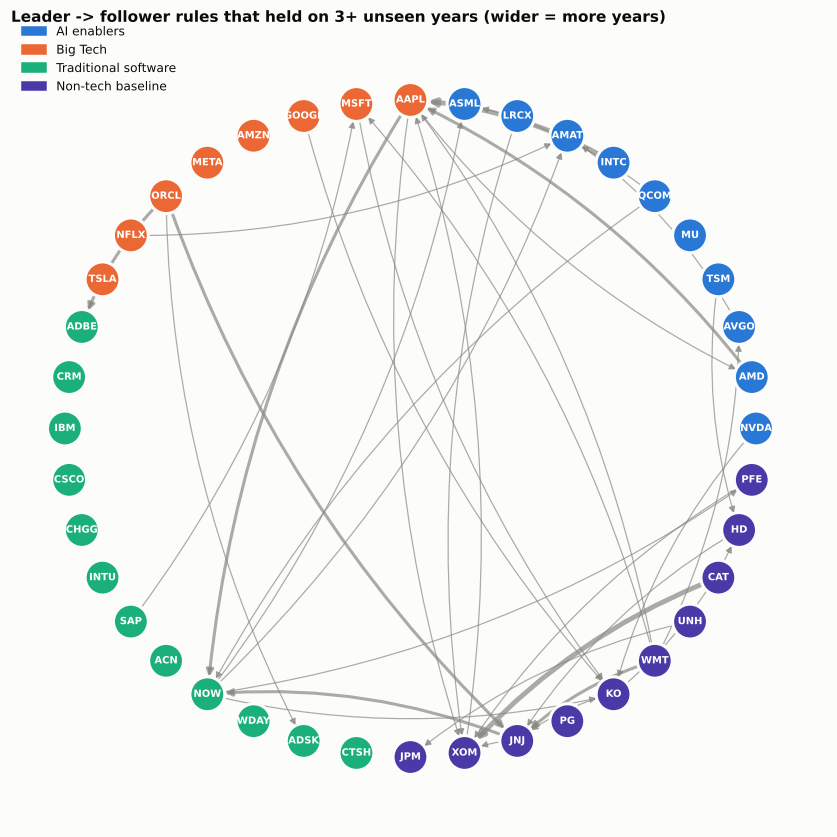

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 7.5), layout="constrained")
pos = nx.circular_layout(TICKERS)        # nodes in group order around the circle
widths = [0.8 + 1.2 * (G[u][v]["weight"] - NETWORK_MIN_YEARS) for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, ax=ax, width=widths, edge_color=MUTED, alpha=0.7, arrows=True, arrowsize=9,
                       connectionstyle="arc3,rad=0.12", node_size=520)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=520, node_color=[GROUP_COLORS[GROUP_OF[t]] for t in TICKERS],
                       edgecolors=SURFACE, linewidths=2)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=6.5, font_color="white", font_weight="bold")
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items()], frameon=False, loc="upper left",
          bbox_to_anchor=(0, 1.02), fontsize=8)
ax.set_title(f"Leader -> follower rules that held on {NETWORK_MIN_YEARS}+ unseen years (wider = more years)")
ax.axis("off")
save(fig, "p1_leader_network")
plt.show()

**Read the network with care.** Thousands of rules were scored, so some edges will repeat by luck. The test that
matters is *persistence*: if a rule worked on last year's unseen data, is it more likely to work on next year's?

In [16]:
rc = real_cls.assign(ok=real_cls["outcome"] == "direction signal")
wide = rc.pivot_table(index="rule", columns="test_year", values="ok", aggfunc="first")
now, nxt_ok = [], []
for Y in wide.columns[:-1]:
    if Y + 1 in wide.columns:
        both = wide[[Y, Y + 1]].dropna()
        now += list(both[Y].astype(bool)); nxt_ok += list(both[Y + 1].astype(bool))
now, nxt_ok = np.array(now), np.array(nxt_ok)
from scipy.stats import fisher_exact
table = [[(now & nxt_ok).sum(), (now & ~nxt_ok).sum()], [(~now & nxt_ok).sum(), (~now & ~nxt_ok).sum()]]
odds, p_persist = fisher_exact(table, alternative="greater")
persist = {"rule_year_pairs": int(len(now)), "p_works_next_if_worked": float(nxt_ok[now].mean()),
           "p_works_next_if_failed": float(nxt_ok[~now].mean()), "fisher_p_one_sided": float(p_persist)}
KEY["part1"]["persistence"] = {k: round(v, 4) for k, v in persist.items()}
pd.Series(persist).round(4)

rule_year_pairs           673.0000
p_works_next_if_worked      0.4463
p_works_next_if_failed      0.3622
fisher_p_one_sided          0.0192
dtype: float64

### 1.5 Has next-day structure changed over time? (link back to the ChatGPT question)

Mine each calendar year on its own and compare with time-shifted copies. The *excess* (real minus null) is a
rough measure of how much next-day structure the market leaves on the table each year.

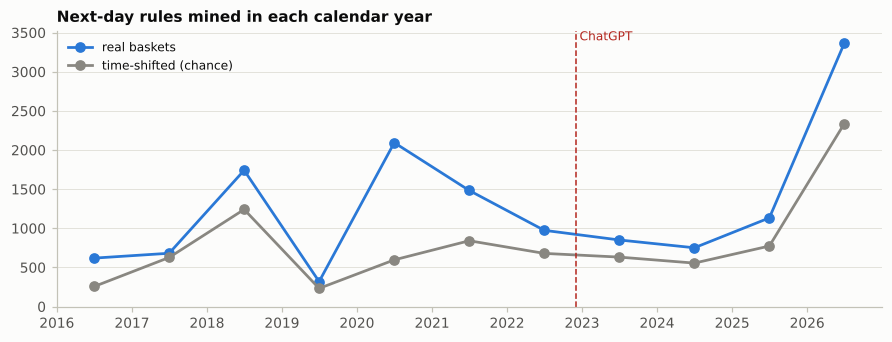

,days,real,null,excess
year,,,,
2016,251,619,256.333333,362.666667
2017,250,681,627.333333,53.666667
2018,250,1741,1241.000000,500.000000
2019,251,319,232.000000,87.000000
2020,252,2094,596.666667,1497.333333
2021,251,1483,841.000000,642.000000
2022,250,974,679.333333,294.666667
2023,249,851,632.000000,219.000000
2024,251,751,555.333333,195.666667


In [17]:
rng_y = np.random.default_rng(SEED + 1)
per_year = []
for Y in range(DAYS[0].year, DAYS[-1].year + 1):
    b = EXT.loc[rows_for_years([Y])]
    real_n = len(mine_rules(b, **LAG_SETTINGS))
    null_n = np.mean([len(mine_rules(time_shift_null(b, rng_y), **LAG_SETTINGS)) for _ in range(N_NULL)])
    per_year.append({"year": Y, "days": len(b), "real": real_n, "null": null_n, "excess": real_n - null_n})
per_year = pd.DataFrame(per_year).set_index("year")
per_year.to_csv(OUT_DIR / "p1_rules_per_calendar_year.csv")
KEY["part1"]["excess_rules_by_year"] = per_year["excess"].round(1).to_dict()

fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
xs = pd.to_datetime([f"{y}-07-01" for y in per_year.index])
ax.plot(xs, per_year["real"], marker="o", color=REAL, label="real baskets")
ax.plot(xs, per_year["null"], marker="o", color=NULL, label="time-shifted (chance)")
ax.set_ylim(bottom=0)
mark_chatgpt(ax)
ax.set_title("Next-day rules mined in each calendar year")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="y")
save(fig, "p1_rules_per_year")
plt.show()
per_year

## Part 2. Do rule features help predict tomorrow?

**Target.** For every stock and day: does the stock **beat the market tomorrow** (residual return > 0)? We also run
plain "goes up tomorrow" (raw return > 0) for comparison; that target is mostly the market's own direction.

**Features, all known at today's close.**

| set | features |
|---|---|
| price (A) | today's residual z-score, 5- and 20-day residual return, 20-day volatility, SPY return today and over 5 days |
| rules (R) | **lag score** up / down / net: sum over next-day rules pointing at this stock whose antecedent happened today, weighted by (confidence - base rate); number of such rules; **rule violation** up / down / net: a same-day rule `X -> stock_UP` whose antecedent happened today but the stock did *not* move (does it catch up tomorrow?); **coupling**: share of same-day rules that fired today |

**No look-ahead.** Rule features for year Y come from rules mined on the three years before Y (the same windows as
Part 1). Models are trained on 2019..Y-1 and tested on Y. Each model sees a test year only once.

**Models.** Logistic regression (readable coefficients) and gradient boosting (can find interactions).
**Metrics.** ROC-AUC (0.5 = coin flip) per test year, a block bootstrap for B - A, and a long/short trading test
with costs, because a small AUC gain is only interesting if it survives trading costs.

In [18]:
SAME_SETTINGS = dict(kind="same", min_support=SAME_MIN_SUPPORT, min_confidence=SAME_MIN_CONFIDENCE,
                     min_lift=SAME_MIN_LIFT, max_len=SAME_MAX_LEN)
STOCK_IDX = {t: i for i, t in enumerate(TICKERS)}
SAME_RULES = {}


def rule_features_for_year(Y):
    # Rule features for every (day in Y, stock), from rules mined only on the three years before Y.
    days = DAYS[DAYS.year == Y]
    di = DAYS.get_indexer(days)
    X = ITEMS_NP[di]
    n, S = len(days), len(TICKERS)
    lag_up, lag_down, lag_n = np.zeros((n, S)), np.zeros((n, S)), np.zeros((n, S))
    viol_up, viol_down = np.zeros((n, S)), np.zeros((n, S))

    lag = LAG_RULES[Y]
    if not lag.empty:
        fired = fired_matrix(lag["antecedent"].tolist(), di)
        weight = (lag["confidence"] - lag["base_rate"]).to_numpy()
        for j, cons in enumerate(lag["consequent"]):
            s = STOCK_IDX[ticker_of(cons)]
            contrib = fired[:, j] * weight[j]
            if direction_of(cons) == "UP":
                lag_up[:, s] += contrib
            else:
                lag_down[:, s] += contrib
            lag_n[:, s] += fired[:, j]

    train_days = DAYS[(DAYS.year >= Y - MINE_YEARS) & (DAYS.year < Y)]
    same = mine_rules(items.loc[train_days], **SAME_SETTINGS)
    SAME_RULES[Y] = same
    coupling = np.zeros(n)
    if not same.empty:
        fired = fired_matrix(same["antecedent"].tolist(), di)
        cons_present = X[:, [TODAY_IDX[c] for c in same["consequent"]]]
        coupling = (fired & cons_present).mean(1)
        violated = fired & ~cons_present
        conf = same["confidence"].to_numpy()
        for j, cons in enumerate(same["consequent"]):
            s = STOCK_IDX[ticker_of(cons)]
            if direction_of(cons) == "UP":
                viol_up[:, s] += violated[:, j] * conf[j]
            else:
                viol_down[:, s] += violated[:, j] * conf[j]

    frames = {"lag_up": lag_up, "lag_down": lag_down, "lag_net": lag_up - lag_down, "lag_n": lag_n,
              "viol_up": viol_up, "viol_down": viol_down, "viol_net": viol_up - viol_down,
              "coupling": np.repeat(coupling[:, None], S, axis=1)}
    long = pd.DataFrame({k: v.ravel() for k, v in frames.items()})
    long["date"] = np.repeat(days, S)
    long["ticker"] = np.tile(TICKERS, n)
    return long


rule_feats = pd.concat([rule_features_for_year(Y) for Y in TEST_YEARS], ignore_index=True)
print(rule_feats.shape, "rows of rule features;", "same-day rules per window:",
      {Y: len(r) for Y, r in SAME_RULES.items()})
rule_feats.describe().T.round(3)

(79160, 10) rows of rule features; same-day rules per window: {2019: 73, 2020: 62, 2021: 105, 2022: 175, 2023: 195, 2024: 114, 2025: 84, 2026: 68}


,count,mean,min,25%,50%,75%,max,std
lag_up,79160.0,0.041252,0.0,0.0,0.0,0.072113,1.545136,0.085922
lag_down,79160.0,0.023193,0.0,0.0,0.0,0.0,1.593385,0.059937
lag_net,79160.0,0.018059,-1.466918,0.0,0.0,0.005193,1.545136,0.099794
lag_n,79160.0,0.752918,0.0,0.0,0.0,1.0,16.0,1.270929
viol_up,79160.0,0.025417,0.0,0.0,0.0,0.0,9.450337,0.207435
viol_down,79160.0,0.029352,0.0,0.0,0.0,0.0,7.605942,0.223392
viol_net,79160.0,-0.003935,-7.605942,0.0,0.0,0.0,9.450337,0.306129
coupling,79160.0,0.038421,0.0,0.0,0.0,0.030769,0.60274,0.080472
date,79160,2022-12-07 04:34:19.221829,2019-01-02 00:00:00,2020-12-16 00:00:00,2022-12-05 00:00:00,2024-11-22 00:00:00,2026-11-13 00:00:00,NaN


In [19]:
def to_long(df, name):
    s = df.stack()
    s.index.names = ["date", "ticker"]
    return s.rename(name)


price_feats = pd.concat([
    to_long(zscore.clip(-6, 6), "z_today"),
    to_long(residual_returns.rolling(5).sum(), "resid_ret_5"),
    to_long(residual_returns.rolling(20).sum(), "resid_ret_20"),
    to_long(stock_returns.rolling(20).std(), "vol_20"),
    to_long(pd.DataFrame({t: market_returns for t in TICKERS}), "spy_ret_1"),
    to_long(pd.DataFrame({t: market_returns.rolling(5).sum() for t in TICKERS}), "spy_ret_5"),
    to_long(residual_returns.shift(-1), "next_resid"),
    to_long(stock_returns.shift(-1), "next_raw"),
], axis=1).reset_index()

panel = rule_feats.merge(price_feats, on=["date", "ticker"], how="left").dropna()
panel["y_residual"] = (panel["next_resid"] > 0).astype(int)
panel["y_raw"] = (panel["next_raw"] > 0).astype(int)
panel["year"] = panel["date"].dt.year

PRICE = ["z_today", "resid_ret_5", "resid_ret_20", "vol_20", "spy_ret_1", "spy_ret_5"]
RULES = ["lag_up", "lag_down", "lag_net", "lag_n", "viol_up", "viol_down", "viol_net", "coupling"]
FEATURE_SETS = {"A: price only": PRICE, "B: price + rules": PRICE + RULES, "R: rules only": RULES}
print(f"Panel: {len(panel):,} stock-days, {panel['date'].nunique()} days, {panel['year'].min()}-{panel['year'].max()}")
print("Share of stock-days that beat the market tomorrow:", panel["y_residual"].mean().round(3),
      "| that go up tomorrow:", panel["y_raw"].mean().round(3))

Panel: 79,120 stock-days, 1978 days, 2019-2026
Share of stock-days that beat the market tomorrow: 0.498 | that go up tomorrow: 0.523


In [20]:
def make_model(name):
    if name == "logistic":
        return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000))
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=300, l2_regularization=1.0, random_state=SEED)


MODEL_TEST_YEARS = [Y for Y in TEST_YEARS if Y >= FIRST_MODEL_TEST_YEAR]


def walk_forward(panel, feature_sets, targets=("y_residual", "y_raw"), models=("logistic", "boosting")):
    preds, coefs = [], []
    for target in targets:
        for model_name in models:
            for fs_name, cols in feature_sets.items():
                for Y in MODEL_TEST_YEARS:
                    train, test = panel[panel["year"] < Y], panel[panel["year"] == Y]
                    m = make_model(model_name).fit(train[cols], train[target])
                    p = m.predict_proba(test[cols])[:, 1]
                    preds.append(pd.DataFrame({"date": test["date"].values, "ticker": test["ticker"].values,
                                               "y": test[target].values, "next_raw": test["next_raw"].values,
                                               "prob": p, "target": target, "model": model_name,
                                               "features": fs_name, "year": Y}))
                    if model_name == "logistic":
                        coefs.append(pd.Series(m[-1].coef_[0], index=cols, name=(target, fs_name, Y)))
    return pd.concat(preds, ignore_index=True), coefs


preds, coefs = walk_forward(panel, FEATURE_SETS)
auc_by_year = (preds.groupby(["target", "model", "features", "year"])
               .apply(lambda d: roc_auc_score(d["y"], d["prob"])).unstack("year"))
auc_by_year["mean"] = auc_by_year.mean(axis=1)
auc_by_year.to_csv(OUT_DIR / "p2_auc_by_year.csv")
auc_by_year.round(4)

year                                    2021    2022    2023    2024    2025  \
target     model    features                                                   
y_raw      boosting A: price only     0.5083  0.4838  0.5388  0.4993  0.5010   
                    B: price + rules  0.5077  0.4909  0.5334  0.5021  0.5292   
                    R: rules only     0.4975  0.4898  0.4878  0.4883  0.5120   
           logistic A: price only     0.5235  0.4882  0.5008  0.4996  0.5120   
                    B: price + rules  0.5203  0.4934  0.4960  0.4994  0.5098   
                    R: rules only     0.4901  0.5037  0.5011  0.4934  0.4989   
y_residual boosting A: price only     0.5068  0.5121  0.5093  0.5099  0.4965   
                    B: price + rules  0.4994  0.5062  0.5134  0.5117  0.5012   
                    R: rules only     0.4930  0.4838  0.4996  0.4986  0.5086   
           logistic A: price only     0.5053  0.5115  0.5144  0.5062  0.4891   
                    B: price + rules  0.5030  0.5036  0.5173  0.5003  0.4930   
                    R: rules only     0.4966  0.4824  0.5038  0.4919  0.5055   

year                                    2026    mean  
target     model    features                          
y_raw      boosting A: price only     0.4858  0.5028  
                    B: price + rules  0.5023  0.5109  
                    R: rules only     0.5156  0.4985  
           logistic A: price only     0.5109  0.5058  
                    B: price + rules  0.5055  0.5041  
                    R: rules only     0.5006  0.4980  
y_residual boosting A: price only     0.5024  0.5062  
                    B: price + rules  0.5015  0.5056  
                    R: rules only     0.4948  0.4964  
           logistic A: price only     0.5053  0.5053  
                    B: price + rules  0.5054  0.5038  
                    R: rules only     0.5024  0.4971

In [21]:
def block_bootstrap_auc_diff(pa, pb, n_boot=300, block=21, seed=SEED):
    # Difference in pooled AUC (B - A), resampling whole 21-day blocks of test days.
    # pa and pb hold the same (date, ticker) rows in the same order.
    rs = np.random.default_rng(seed)
    d = pa["date"].to_numpy()
    days, starts = np.unique(d, return_index=True)
    ends = np.append(starts[1:], len(d))
    blocks = [np.arange(starts[i], ends[min(i + block, len(days)) - 1]) for i in range(0, len(days), block)]
    ya, qa, qb = pa["y"].to_numpy(), pa["prob"].to_numpy(), pb["prob"].to_numpy()
    diffs = []
    for _ in range(n_boot):
        idx = np.concatenate([blocks[i] for i in rs.integers(0, len(blocks), len(blocks))])
        diffs.append(roc_auc_score(ya[idx], qb[idx]) - roc_auc_score(ya[idx], qa[idx]))
    return np.percentile(diffs, [2.5, 50, 97.5])


def key_of(target, model, fs):
    return preds[(preds.target == target) & (preds.model == model) & (preds.features == fs)].sort_values(["date", "ticker"])


comparison = []
for target in ["y_residual", "y_raw"]:
    for model_name in ["logistic", "boosting"]:
        pa, pb = key_of(target, model_name, "A: price only"), key_of(target, model_name, "B: price + rules")
        assert (pa["date"].to_numpy() == pb["date"].to_numpy()).all() and (pa["ticker"].to_numpy() == pb["ticker"].to_numpy()).all()
        lo, mid, hi = block_bootstrap_auc_diff(pa, pb)
        yrs = auc_by_year.loc[(target, model_name)]
        comparison.append({"target": target, "model": model_name,
                           "AUC A (pooled)": roc_auc_score(pa["y"], pa["prob"]),
                           "AUC B (pooled)": roc_auc_score(pb["y"], pb["prob"]),
                           "B - A": mid, "95% CI low": lo, "95% CI high": hi,
                           "years B > A": int((yrs.loc["B: price + rules", MODEL_TEST_YEARS] > yrs.loc["A: price only", MODEL_TEST_YEARS]).sum()),
                           "of years": len(MODEL_TEST_YEARS)})
comparison = pd.DataFrame(comparison)
comparison.to_csv(OUT_DIR / "p2_model_comparison.csv", index=False)
KEY["part2"] = {"comparison": comparison.round(4).to_dict(orient="records")}
comparison.round(4)

,target,model,AUC A (pooled),AUC B (pooled),B - A,95% CI low,95% CI high,years B > A,of years
0,y_residual,logistic,0.5054,0.5036,-0.0017,-0.0045,0.0011,3,6
1,y_residual,boosting,0.5058,0.5055,-0.0003,-0.0047,0.0038,3,6
2,y_raw,logistic,0.5038,0.5025,-0.0010,-0.0071,0.0047,1,6
3,y_raw,boosting,0.5006,0.5068,0.0059,-0.0028,0.0151,4,6


### 2.1 Which rule features does the model use?

Logistic-regression coefficients on standardised features (residual target, model B), one bar per feature with
the range across the yearly refits. Positive = makes "beats the market tomorrow" more likely. A coefficient that
flips sign from year to year is not a stable signal.

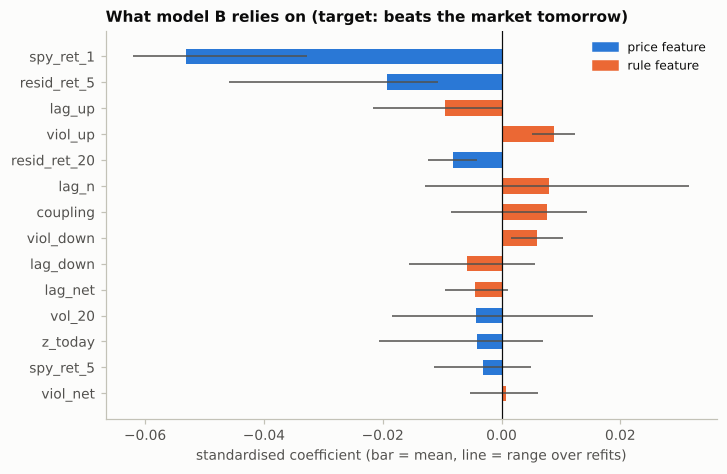

,mean,min,max,same sign every year
viol_net,0.0007,-0.0053,0.0061,False
spy_ret_5,-0.0031,-0.0114,0.0049,False
z_today,-0.0042,-0.0206,0.0070,False
vol_20,-0.0043,-0.0184,0.0154,False
lag_net,-0.0045,-0.0095,0.0011,False
lag_down,-0.0059,-0.0156,0.0057,False
viol_down,0.0059,0.0017,0.0103,True
coupling,0.0077,-0.0085,0.0144,False
lag_n,0.0080,-0.0129,0.0316,False
resid_ret_20,-0.0082,-0.0125,-0.0041,True


In [22]:
cb = pd.DataFrame([c for c in coefs if c.name[0] == "y_residual" and c.name[1] == "B: price + rules"])
summary_coef = pd.DataFrame({"mean": cb.mean(), "min": cb.min(), "max": cb.max(),
                             "same sign every year": (np.sign(cb) == np.sign(cb.mean())).all()})
summary_coef = summary_coef.reindex(summary_coef["mean"].abs().sort_values().index)
KEY["part2"]["logistic_coefficients_B"] = summary_coef.round(4).to_dict(orient="index")

fig, ax = plt.subplots(figsize=(6.5, 4.2), layout="constrained")
yy = np.arange(len(summary_coef))
colors = [MODEL_COLORS["B: price + rules"] if f in RULES else MODEL_COLORS["A: price only"] for f in summary_coef.index]
ax.barh(yy, summary_coef["mean"], color=colors, height=0.6)
ax.hlines(yy, summary_coef["min"], summary_coef["max"], color=INK_SOFT, lw=1)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(yy, summary_coef.index)
ax.set_xlabel("standardised coefficient (bar = mean, line = range over refits)")
ax.legend(handles=[Patch(color=MODEL_COLORS["A: price only"], label="price feature"),
                   Patch(color=MODEL_COLORS["B: price + rules"], label="rule feature")], frameon=False, fontsize=8)
ax.set_title("What model B relies on (target: beats the market tomorrow)")
save(fig, "p2_coefficients")
plt.show()
summary_coef.round(4)

### 2.2 Trading test: is the edge worth anything after costs?

Each day, rank the 40 stocks by predicted probability, buy the top 20% and short the bottom 20% (equal weights),
hold one day. Gross return, then net of `COST_BPS` per unit of turnover. This is a sanity check, not an
investment strategy.

In [23]:
def long_short(p, top=TOP_FRACTION, cost_bps=COST_BPS):
    rets, turnover, prev = [], [], None
    for d, g in p.groupby("date"):
        k = max(1, int(round(top * len(g))))
        g = g.sort_values("prob")
        w = pd.Series(0.0, index=g["ticker"])
        w[g["ticker"].iloc[-k:]] = 1 / k
        w[g["ticker"].iloc[:k]] = -1 / k
        rets.append((w * g.set_index("ticker")["next_raw"]).sum())
        turnover.append(w.abs().sum() if prev is None else w.sub(prev, fill_value=0).abs().sum())
        prev = w
    rets, turnover = np.array(rets), np.array(turnover)
    net = rets - turnover * cost_bps / 1e4
    sharpe = lambda r: np.sqrt(252) * r.mean() / r.std() if r.std() > 0 else np.nan
    return {"gross % per year": 252 * rets.mean() * 100, "net % per year": 252 * net.mean() * 100,
            "gross Sharpe": sharpe(rets), "net Sharpe": sharpe(net), "hit rate": (rets > 0).mean(),
            "mean daily turnover": turnover.mean(),
            "break-even cost (bps)": 1e4 * rets.mean() / turnover.mean()}, pd.Series(net, index=sorted(p["date"].unique()))


trading, curves = [], {}
for (target, model_name, fs), p in preds.groupby(["target", "model", "features"]):
    stats, net = long_short(p)
    trading.append({"target": target, "model": model_name, "features": fs, **stats})
    curves[(target, model_name, fs)] = net
trading = pd.DataFrame(trading)
trading.to_csv(OUT_DIR / "p2_trading_test.csv", index=False)
KEY["part2"]["trading"] = trading.round(4).to_dict(orient="records")
trading.round(3)

,target,model,features,gross % per year,net % per year,gross Sharpe,net Sharpe,hit rate,mean daily turnover,break-even cost (bps)
0,y_raw,boosting,A: price only,-5.293,-40.033,-0.214,-1.617,0.479,2.757,-0.762
1,y_raw,boosting,B: price + rules,-2.757,-37.976,-0.113,-1.550,0.485,2.795,-0.391
2,y_raw,boosting,R: rules only,-5.143,-39.447,-0.255,-1.959,0.488,2.723,-0.750
3,y_raw,logistic,A: price only,-20.887,-47.505,-0.733,-1.667,0.464,2.113,-3.924
4,y_raw,logistic,B: price + rules,-24.695,-50.348,-0.868,-1.770,0.455,2.036,-4.813
5,y_raw,logistic,R: rules only,-13.311,-43.203,-0.598,-1.941,0.470,2.372,-2.227
6,y_residual,boosting,A: price only,0.746,-32.984,0.030,-1.326,0.485,2.677,0.111
7,y_residual,boosting,B: price + rules,-2.881,-37.221,-0.115,-1.487,0.494,2.725,-0.420
8,y_residual,boosting,R: rules only,-8.147,-40.707,-0.407,-2.032,0.476,2.584,-1.251
9,y_residual,logistic,A: price only,-28.118,-45.511,-0.890,-1.441,0.479,1.380,-8.084


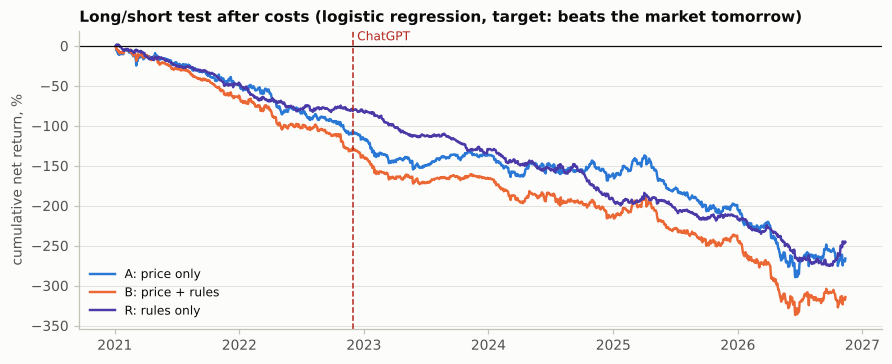

In [24]:
fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
for fs in ["A: price only", "B: price + rules", "R: rules only"]:
    c = curves[("y_residual", "logistic", fs)].cumsum() * 100
    ax.plot(c.index, c.values, color=MODEL_COLORS[fs], label=fs, lw=1.6)
ax.axhline(0, color=INK, lw=0.8)
ax.set_ylabel("cumulative net return, %")
ax.set_title("Long/short test after costs (logistic regression, target: beats the market tomorrow)")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="y")
mark_chatgpt(ax)
save(fig, "p2_trading_curves")
plt.show()

### 2.3 Why does the price-only logistic model lose money before costs?

Its biggest stock-specific coefficient is on the 5-day residual return, and it is negative: it learned "last week's
losers bounce back" (short-term reversal), a classic effect. Below is that one-feature strategy on its own: each
day buy the 8 stocks with the worst 5-day residual return and short the 8 best, hold one day, before costs.

{"2016-2020": {"gross_pct_per_year": 13.03, "t_stat": 1.42}, "2021-2026": {"gross_pct_per_year": -14.27, "t_stat": -1.13}}


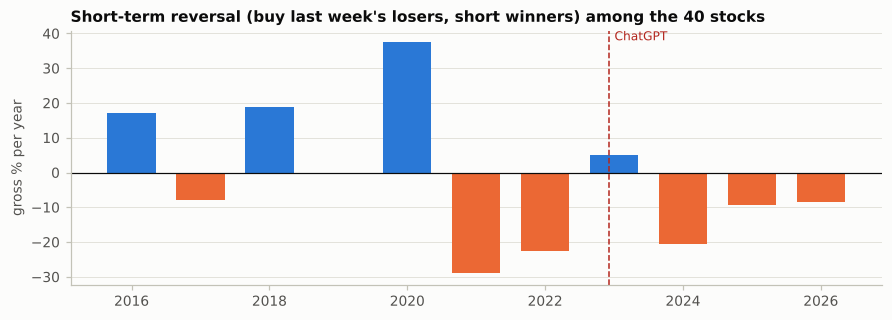

,gross_pct_per_year,t_stat
date,,
2016,17.04,0.94
2017,-7.98,-0.50
2018,18.85,0.93
2019,-0.29,-0.02
2020,37.40,1.32
2021,-28.92,-1.15
2022,-22.50,-0.92
2023,4.94,0.24
2024,-20.55,-0.74


In [25]:
signal = -residual_returns.rolling(5).sum()
next_raw_wide = stock_returns.shift(-1)
rev = []
for d in signal.loc[STUDY_START:].index[:-1]:
    order = signal.loc[d].dropna().sort_values()
    r = next_raw_wide.loc[d]
    rev.append({"date": d, "ret": r[order.index[-8:]].mean() - r[order.index[:8]].mean()})
rev = pd.DataFrame(rev).set_index("date")["ret"]
rev_year = rev.groupby(rev.index.year).agg(gross_pct_per_year=lambda x: 252 * x.mean() * 100,
                                           t_stat=lambda x: x.mean() / x.std() * np.sqrt(len(x)))
split = {"2016-2020": rev.loc[:"2020"], "2021-2026": rev.loc["2021":]}
KEY["part2"]["reversal"] = {k: {"gross_pct_per_year": round(252 * v.mean() * 100, 2),
                                "t_stat": round(v.mean() / v.std() * np.sqrt(len(v)), 2)} for k, v in split.items()}
print(json.dumps(KEY["part2"]["reversal"]))

fig, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
ax.bar(rev_year.index, rev_year["gross_pct_per_year"], color=[REAL if v >= 0 else MODEL_COLORS["B: price + rules"] for v in rev_year["gross_pct_per_year"]], width=0.7)
ax.axhline(0, color=INK, lw=0.8)
ax.axvline(2022.92, color=HIGHLIGHT, lw=1, ls="--"); ax.text(2022.95, ax.get_ylim()[1], " ChatGPT", color=HIGHLIGHT, va="top", fontsize=8)
ax.set_ylabel("gross % per year")
ax.set_title("Short-term reversal (buy last week's losers, short winners) among the 40 stocks")
ax.grid(axis="y")
save(fig, "p2_reversal_by_year")
plt.show()
rev_year.round(2)

### What Part 2 shows
* Every model is within about 0.01 of a coin flip (AUC 0.49-0.51). For liquid large caps that is normal at a
  one-day horizon.
* Adding rule features (B vs A) changes AUC by between -0.002 and +0.006; every bootstrap interval includes zero,
  and B beats A in only 1-4 of 6 test years. Rule features alone (R) are slightly *below* 0.5.
* The coefficient plot agrees: only `viol_up` and `viol_down` keep the same sign every year, and both are tiny.
* The trading test turns over most of the book every day, so 5 bps per trade costs 30-40% a year, far more than any
  gross edge (the best break-even cost is 0.1 bps, against 5 bps charged).
* The price-only logistic model loses money even before costs because it learned short-term reversal from
  2019-2020, and reversal stopped working in these stocks from 2021 (section 2.3).

## Part 3. Market regimes: clustering trading days, then mining rules inside each regime

**Daily market state** (all computed from data up to that day): SPY 20-day volatility, SPY 20-day return,
cross-sectional dispersion of the 40 stocks, their average pairwise correlation over 60 days, and how many
items (major moves) happen per day on average over 20 days.

We cluster these with **k-means** and a **Gaussian mixture**, pick the number of regimes with silhouette and BIC,
and check the two algorithms agree (adjusted Rand index). Then:

1. *Describe* the regimes (when they happen, what they look like).
2. *Mine next-day rules inside each regime* on 2016-2021 and test them on the same regime in 2022-2026.
   Question: do next-day rules hold up better in stressed markets, when diversification fails?
3. *Model C* = model B + the regime of the day, fitted inside each walk-forward fold.

In [26]:
def avg_pairwise_corr(rets, window=60):
    out = pd.Series(np.nan, index=rets.index)
    a = rets.to_numpy()
    iu = np.triu_indices(a.shape[1], 1)
    for i in range(window, len(a) + 1):
        c = np.corrcoef(a[i - window:i].T)
        out.iloc[i - 1] = np.nanmean(c[iu])
    return out


state = pd.DataFrame({
    "log_vol_20": np.log(market_returns.rolling(20).std() * np.sqrt(252)),
    "spy_ret_20": market_returns.rolling(20).sum(),
    "log_dispersion_20": np.log(stock_returns.std(axis=1).rolling(20).mean()),
    "avg_corr_60": avg_pairwise_corr(stock_returns.fillna(0)),
    "activity_20": items.reindex(stock_returns.index).mean(axis=1).rolling(20).mean(),
}).loc[STUDY_START:].dropna()
STATE_COLS = list(state.columns)
Zs = np.clip(StandardScaler().fit_transform(state), -REGIME_CLIP, REGIME_CLIP)

choice = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Zs)
    gm = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=SEED).fit(Zs)
    choice.append({"k": k, "k-means silhouette": silhouette_score(Zs, km.labels_),
                   "GMM BIC": gm.bic(Zs), "ARI k-means vs GMM": adjusted_rand_score(km.labels_, gm.predict(Zs))})
choice = pd.DataFrame(choice).set_index("k")
KEY["part3"] = {"model_choice": choice.round(4).to_dict(orient="index")}
choice.round(3)

,k-means silhouette,GMM BIC,ARI k-means vs GMM
k,,,
2,0.243,31417.443,0.196
3,0.265,30688.734,0.588
4,0.281,30350.080,0.560
5,0.242,29934.755,0.578
6,0.212,29388.367,0.365


In [27]:
def fit_regimes(X_train, k=N_REGIMES, clip=REGIME_CLIP):
    # k-means on standardised (and capped) state features; clusters renamed 0 = calmest ... k-1 = most stressed.
    scaler = StandardScaler().fit(X_train)
    prep = lambda X: np.clip(scaler.transform(X), -clip, clip)
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(prep(X_train))
    order = np.argsort(km.cluster_centers_[:, STATE_COLS.index("log_vol_20")])
    rename = {int(old): new for new, old in enumerate(order)}
    return lambda X: np.array([rename[int(c)] for c in km.predict(prep(X))])


REGIME_NAMES = ["Calm", "Normal", "Stress"] if N_REGIMES == 3 else [f"R{i}" for i in range(N_REGIMES)]
assign_all = fit_regimes(state)                    # descriptive fit on all days (section 3.1 only)
regime = pd.Series(assign_all(state), index=state.index, name="regime")

profile = state.assign(regime=regime, spy_ret_1=market_returns.reindex(state.index)).groupby("regime").agg(
    share_of_days=("log_vol_20", lambda s: len(s) / len(state)),
    spy_vol_ann=("log_vol_20", lambda s: np.exp(s).mean()),
    avg_corr=("avg_corr_60", "mean"), items_per_day=("activity_20", lambda s: s.mean() * len(ITEMS)),
    spy_mean_daily_ret_pct=("spy_ret_1", lambda s: s.mean() * 100))
profile.index = [REGIME_NAMES[i] for i in profile.index]

gm3 = GaussianMixture(n_components=N_REGIMES, covariance_type="full", n_init=3, random_state=SEED).fit(Zs)
ari3 = adjusted_rand_score(regime, gm3.predict(Zs))

# longest stress spells, to check the clusters against known market events
stress = (regime == N_REGIMES - 1).astype(int)
spell_id = (stress.diff() != 0).cumsum()
spells = (pd.DataFrame({"stress": stress, "id": spell_id}).reset_index().rename(columns={"index": "date", "Date": "date"})
          .query("stress == 1").groupby("id")["date"].agg(["first", "last", "count"]).sort_values("count", ascending=False).head(8))
KEY["part3"]["profile"] = profile.round(4).to_dict(orient="index")
KEY["part3"]["ari_kmeans_vs_gmm_k3"] = round(float(ari3), 4)
KEY["part3"]["longest_stress_spells"] = [f"{a.date()} to {b.date()} ({c} days)" for a, b, c in spells.to_numpy()]
print(f"k-means vs GMM agreement at k={N_REGIMES}: ARI = {ari3:.2f}")
display(profile.round(3))
spells

k-means vs GMM agreement at k=3: ARI = 0.59


,share_of_days,spy_vol_ann,avg_corr,items_per_day,spy_mean_daily_ret_pct
Calm,0.442,0.094,0.289,8.427,0.046
Normal,0.281,0.130,0.191,10.904,0.093
Stress,0.277,0.250,0.496,9.894,0.058


,first,last,count
id,,,
25,2022-02-11,2023-04-05,288
17,2020-02-24,2020-07-28,109
7,2018-10-16,2019-02-19,85
5,2018-02-05,2018-05-07,64
29,2025-04-03,2025-07-07,64
1,2016-02-01,2016-03-18,34
21,2020-09-08,2020-10-14,27
13,2019-08-08,2019-09-11,24


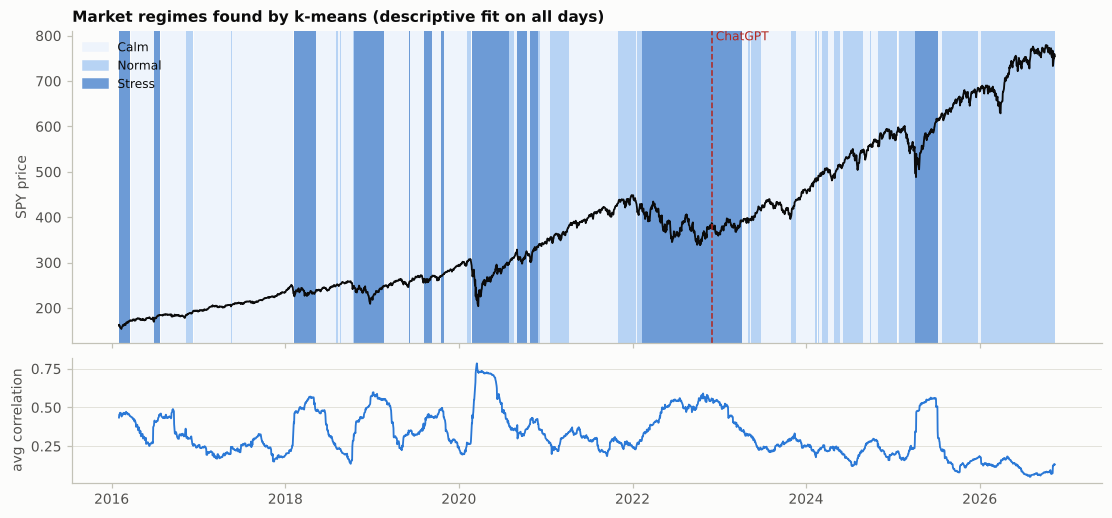

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True, layout="constrained", height_ratios=[3, 1.2])
ax = axes[0]
spy = prices[MARKET].loc[state.index]
ax.plot(spy.index, spy.values, color=INK, lw=1.2, zorder=2)
seg = (regime != regime.shift()).cumsum()
for _, g in regime.groupby(seg):
    ax.axvspan(g.index[0], g.index[-1] + pd.Timedelta(days=1), color=REGIME_COLORS[g.iloc[0]], lw=0, zorder=0)
ax.set_ylabel("SPY price")
ax.legend(handles=[Patch(color=REGIME_COLORS[i], label=n) for i, n in enumerate(REGIME_NAMES)], frameon=False,
          fontsize=8, loc="upper left")
ax.set_title("Market regimes found by k-means (descriptive fit on all days)")
mark_chatgpt(ax)
ax = axes[1]
ax.plot(state.index, state["avg_corr_60"], color=REAL, lw=1.2)
ax.set_ylabel("avg correlation")
ax.grid(axis="y")
save(fig, "p3_regime_timeline")
plt.show()

### 3.2 Next-day rules inside each regime

Regimes are now fitted on 2016-2021 only and applied to 2022-2026, so the test years stay unseen. Rules for each
regime are mined on that regime's training days and scored on the same regime's test days.

In [29]:
train_state = state[state.index.year <= REGIME_TRAIN_END]
assign_split = fit_regimes(train_state)
regime_split = pd.Series(assign_split(state), index=state.index)
stability = adjusted_rand_score(regime, regime_split)
KEY["part3"]["ari_fit_2016_2021_vs_fit_all"] = round(float(stability), 4)
print(f"Regimes fitted on 2016-2021 vs on all days agree with ARI = {stability:.2f}")

rng_r = np.random.default_rng(SEED + 2)
reg_rows, reg_rules = [], {}
train_rows = rows_for_years(range(DAYS[0].year, REGIME_TRAIN_END + 1))
test_rows = NEXT_DAY.index[NEXT_DAY.index.year > REGIME_TRAIN_END]
for r in range(N_REGIMES):
    tr = train_rows[(regime_split.reindex(train_rows) == r).to_numpy()]
    te = test_rows[(regime_split.reindex(test_rows) == r).to_numpy()]
    b = EXT.loc[tr]
    rules = mine_rules(b, **LAG_SETTINGS)
    scored = classify(evaluate_out_of_sample(rules, te))
    scored["test_year"] = 0
    null = pd.concat([mine_rules(time_shift_null(b, rng_r), **LAG_SETTINGS) for _ in range(N_NULL)], ignore_index=True)
    null_scored = classify(evaluate_out_of_sample(null, te))
    reg_rules[REGIME_NAMES[r]] = scored
    reg_rows.append({"regime": REGIME_NAMES[r], "train days": len(tr), "test days": len(te),
                     "rules (real)": len(rules), "rules (null, mean)": len(null) / N_NULL,
                     "scored": len(scored),
                     "test lift median (real)": scored["test_lift"].median() if len(scored) else np.nan,
                     "test lift median (null)": null_scored["test_lift"].median() if len(null_scored) else np.nan,
                     "direction signal share (real)": (scored["outcome"] == "direction signal").mean() if len(scored) else np.nan,
                     "direction signal share (null)": (null_scored["outcome"] == "direction signal").mean() if len(null_scored) else np.nan,
                     "volatility-only share (real)": (scored["outcome"] == "volatility only").mean() if len(scored) else np.nan})
reg_table = pd.DataFrame(reg_rows).set_index("regime")
reg_table.to_csv(OUT_DIR / "p3_rules_by_regime.csv")
KEY["part3"]["rules_by_regime"] = reg_table.round(4).to_dict(orient="index")
reg_table.round(3)

Regimes fitted on 2016-2021 vs on all days agree with ARI = 0.32


,train days,test days,rules (real),"rules (null, mean)",scored,test lift median (real),test lift median (null),direction signal share (real),direction signal share (null),volatility-only share (real)
regime,,,,,,,,,,
Calm,810,557,181,96.000,181,1.010,1.035,0.376,0.424,0.133
Normal,439,288,129,84.333,129,1.029,1.083,0.403,0.439,0.109
Stress,242,376,9346,3289.000,8896,1.119,1.119,0.424,0.426,0.156


The table below is the **top 12 of several thousand** scored stress rules, each judged on as few as 5 test days.
That is what the best of many coin flips looks like; the regime table above, which compares real with null
rules, is the evidence. Use these only as examples of what a rule looks like.

In [30]:
top_stress = reg_rules[REGIME_NAMES[-1]]
top_stress = top_stress[(top_stress["outcome"] == "direction signal") & (~top_stress["self"])]
cols = ["rule", "confidence", "lift", "n_ante", "test_fired", "test_confidence", "test_mirror_confidence", "test_lift"]
top_stress = top_stress.sort_values("test_lift", ascending=False)[cols].head(12)
top_stress.to_csv(OUT_DIR / "p3_top_stress_rules.csv", index=False)
top_stress.round(3)

,rule,confidence,lift,n_ante,test_fired,test_confidence,test_mirror_confidence,test_lift
356,CAT_UP & NVDA_UP -> MSFT_UP+1,0.750,4.033,8,5,0.800,0.000,5.675
4889,ADBE_UP & ASML_UP -> MSFT_UP+1,0.400,2.151,20,5,0.800,0.000,5.675
2446,ADBE_UP & ORCL_UP -> IBM_UP+1,0.385,2.738,13,5,0.600,0.000,5.502
6660,AAPL_UP & CSCO_UP -> WMT_UP+1,0.312,1.801,16,7,0.714,0.000,5.481
1224,LRCX_UP & NFLX_UP -> NVDA_UP+1,0.556,3.201,9,6,0.833,0.167,5.311
7583,ADBE_UP & ASML_UP -> AMD_UP+1,0.250,1.635,20,5,0.800,0.000,5.277
638,ASML_UP & SAP_UP -> QCOM_UP+1,0.455,3.667,11,10,0.700,0.000,5.264
1636,GOOGL_UP & NOW_UP -> ADSK_DOWN+1,0.312,3.025,16,5,0.800,0.200,4.931
659,ASML_UP & CRM_UP -> PG_DOWN+1,0.556,3.634,9,5,0.600,0.000,4.904
1185,CHGG_DOWN & NOW_DOWN -> AMAT_DOWN+1,0.455,3.235,11,5,0.600,0.000,4.800


### 3.3 Model C: does knowing the regime help the prediction?

Inside every walk-forward fold, regimes are fitted on the training days only, then the regime of each day becomes
a feature (one-hot), plus the two rule scores multiplied by a "stress day" flag so logistic regression can give
rules a different weight in stressed markets.

In [31]:
def add_regime_features(panel_part, assign):
    st = state.reindex(panel_part["date"])
    reg = assign(st.to_numpy()) if len(st) else np.array([])
    out = panel_part.copy()
    for r in range(N_REGIMES):
        out[f"regime_{r}"] = (reg == r).astype(int)
    stress_flag = (reg == N_REGIMES - 1).astype(int)
    out["lag_net_x_stress"] = out["lag_net"] * stress_flag
    out["viol_net_x_stress"] = out["viol_net"] * stress_flag
    return out


REGIME_FEATS = [f"regime_{r}" for r in range(N_REGIMES)] + ["lag_net_x_stress", "viol_net_x_stress"]
C_COLS = PRICE + RULES + REGIME_FEATS
panel_s = panel[panel["date"].isin(state.index)]
predsC = []
for target in ["y_residual", "y_raw"]:
    for model_name in ["logistic", "boosting"]:
        for Y in MODEL_TEST_YEARS:
            train_days_state = state[state.index.year < Y]
            assign = fit_regimes(train_days_state)
            train = add_regime_features(panel_s[panel_s["year"] < Y], lambda X: assign(pd.DataFrame(X, columns=STATE_COLS)))
            test = add_regime_features(panel_s[panel_s["year"] == Y], lambda X: assign(pd.DataFrame(X, columns=STATE_COLS)))
            m = make_model(model_name).fit(train[C_COLS], train[target])
            predsC.append(pd.DataFrame({"date": test["date"].values, "ticker": test["ticker"].values,
                                        "y": test[target].values, "next_raw": test["next_raw"].values,
                                        "prob": m.predict_proba(test[C_COLS])[:, 1], "target": target,
                                        "model": model_name, "features": "C: B + regime", "year": Y}))
predsC = pd.concat(predsC, ignore_index=True)

final = []
for target in ["y_residual", "y_raw"]:
    for model_name in ["logistic", "boosting"]:
        row = {"target": target, "model": model_name}
        for fs in ["A: price only", "B: price + rules", "R: rules only"]:
            p = key_of(target, model_name, fs)
            p = p[p["date"].isin(state.index)]
            row[fs] = roc_auc_score(p["y"], p["prob"])
        pc = predsC[(predsC.target == target) & (predsC.model == model_name)]
        row["C: B + regime"] = roc_auc_score(pc["y"], pc["prob"])
        statsC, netC = long_short(pc)
        curves[(target, model_name, "C: B + regime")] = netC
        row["C net Sharpe"] = statsC["net Sharpe"]
        final.append(row)
final = pd.DataFrame(final)
final.to_csv(OUT_DIR / "p3_final_auc_table.csv", index=False)
KEY["part3"]["final_auc"] = final.round(4).to_dict(orient="records")
final.round(4)

,target,model,A: price only,B: price + rules,R: rules only,C: B + regime,C net Sharpe
0,y_residual,logistic,0.5054,0.5036,0.4944,0.5056,-1.9518
1,y_residual,boosting,0.5058,0.5055,0.4944,0.5043,-1.5131
2,y_raw,logistic,0.5038,0.5025,0.4900,0.4957,-1.8637
3,y_raw,boosting,0.5006,0.5068,0.4961,0.5040,-1.1124


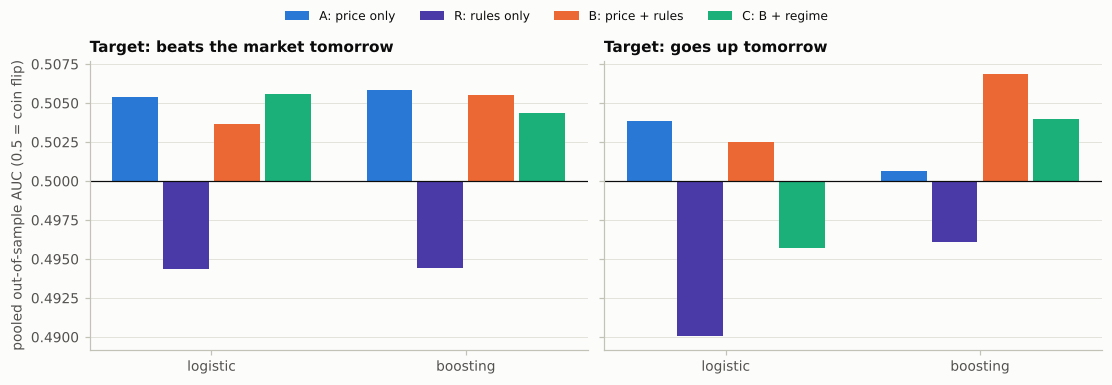

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained", sharey=True)
order = ["A: price only", "R: rules only", "B: price + rules", "C: B + regime"]
for ax, target, title in zip(axes, ["y_residual", "y_raw"], ["Target: beats the market tomorrow", "Target: goes up tomorrow"]):
    sub = final[final.target == target].set_index("model")
    xx = np.arange(len(sub.index))
    w = 0.2
    for i, fs in enumerate(order):
        ax.bar(xx + (i - 1.5) * w, sub[fs] - 0.5, w * 0.9, bottom=0.5, color=MODEL_COLORS[fs], label=fs)
    ax.axhline(0.5, color=INK, lw=0.8)
    ax.set_xticks(xx, sub.index)
    ax.set_title(title)
    ax.grid(axis="y")
axes[0].set_ylabel("pooled out-of-sample AUC (0.5 = coin flip)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncol=4, frameon=False, fontsize=8)
save(fig, "p3_model_auc_comparison")
plt.show()

### What Part 3 shows
* The clusters are meaningful but not sharp: silhouette about 0.27, k-means and a Gaussian mixture agree with
  ARI 0.59 at k = 3, and refitting on 2016-2021 only gives ARI 0.32 against the all-days fit. Regimes describe the
  market well, but their exact borders depend on the data used to fit them.
* The stress regime is where stocks move together (average correlation 0.50) and where next-day rules multiply
  (2.8x chance). Out of sample, those rules still predict volatility rather than direction.
* Knowing the regime does not improve the prediction (model C vs B).
* Average correlation among the 40 stocks fell to about 0.1 in 2026, the lowest in the sample (bottom panel of
  the timeline): stocks are moving on their own news more than ever.

## Key numbers
Everything quoted in slides or the report should come from this file.

In [33]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, float) and np.isnan(o):
        return None
    return o


(OUT_DIR / "key_numbers.json").write_text(json.dumps(to_jsonable(KEY), indent=1))
print("wrote", OUT_DIR / "key_numbers.json")

wrote outputs/lag/key_numbers.json
